# Modelo 1 · Próximo movimiento de la competencia
## Notebook 2: la tarea, la métrica y el baseline

**La pregunta.** Para cada producto en cada comercio y cada día: *¿bajará su precio al menos 5 % frente al de hoy?*

| Tarea | Horizonte | Para qué sirve |
|---|---|---|
| **A** | en algún día de los **próximos 7** | lista semanal de productos a vigilar |
| **B** | **mañana** | la fecha exacta, para preparar el precio a tiempo |

**La métrica a seguir: AP (precisión promedio).** El modelo ordena todos los casos de mayor a menor riesgo; la AP mide qué tan arriba quedan las bajas reales (de 0 a 1). Se usa porque las bajas son pocas (≈9 % en A, ≈1 % en B): un modelo que diga "nunca baja" acierta 91 % y no sirve. **Para el negocio** se traduce en *aciertos por cada 100 alertas* (las del 5 % de mayor riesgo).

**Cortes de tiempo** (nunca al azar): entrenamiento 2023–2024 · validación ene–jun 2025 · prueba jul–dic 2025 (la guarda Pycca).

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
warnings.filterwarnings('ignore')
RAIZ = Path('..') if Path('../variables.py').exists() else Path('.')     # repo (notebooks/) o paquete de ESPOL
sys.path.insert(0, str(RAIZ)); sys.path.insert(0, '.')
import estilo; estilo.aplicar()
from estilo import AZUL, NARANJA, AQUA, TINTA2, GRIS, pie
DATOS = RAIZ / 'datos'
pd.set_option('display.width', 160)
import variables as V
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
CORTES = {'entrenamiento': ('2023-01-01', '2024-12-31'), 'validacion': ('2025-01-01', '2025-06-30'), 'prueba': ('2025-07-01', '2025-12-24')}

### 1. Objetivo y variables (solo con información hasta el día *t*)

In [2]:
d, cal = V.cargar(DATOS)
for nombre, h in (('y_A', 7), ('y_B', 1)):
    V.HORIZONTE = h
    d[nombre] = V.objetivo(d)
X = V.variables(d, cal)
cortes = {k: X[(X.fecha >= a) & (X.fecha <= b)] for k, (a, b) in CORTES.items()}
cortes = {k: x for k, x in cortes.items() if x.y_A.notna().any()}
EVAL = [k for k in ('validacion', 'prueba') if k in cortes]
print('Variables del baseline (', len(V.COLUMNAS), '):', ', '.join(V.COLUMNAS))
pd.DataFrame({k: {'filas': int(x.y_A.notna().sum()), '% bajas tarea A': round(100 * x.y_A.mean(), 2), '% bajas tarea B': round(100 * x.y_B.mean(), 2)}
              for k, x in cortes.items()}).T

Variables del baseline ( 23 ): comercio_cod, division_cod, tachado, desc_actual, en_oferta_hoy, cambio_1d, cambio_7d, cambio_30d, vs_max_30d, vs_min_90d, dias_sin_cambio, ofertas_90d, inicios_oferta_365d, bajas_prod_7d, bajas_otros_7d, vs_mediana_comercios, n_comercios, evento_activo, dias_a_evento, dias_a_black_friday, dia_semana, dia_mes, mes


,filas,% bajas tarea A,% bajas tarea B
entrenamiento,2590270.0,8.08,1.22
validacion,626935.0,7.46,1.18


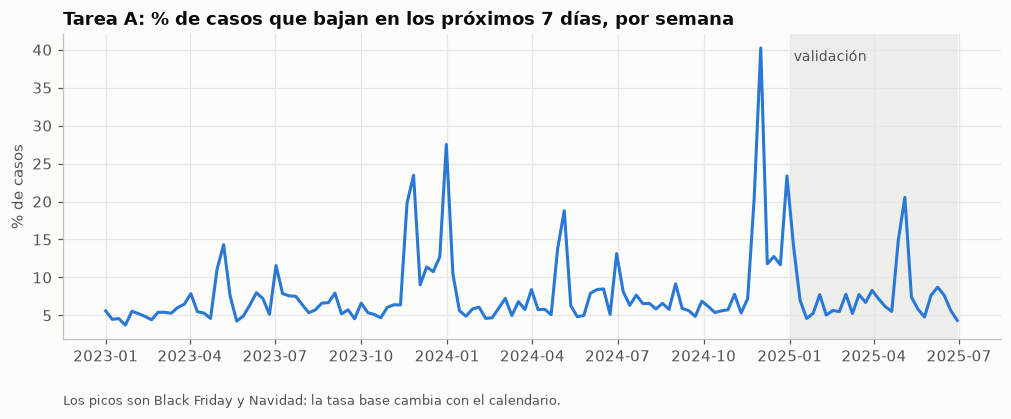

In [3]:
s = X.dropna(subset=['y_A']).groupby(pd.Grouper(key='fecha', freq='W')).y_A.mean() * 100
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(s.index, s.values, color=AZUL)
for k, (a, b) in CORTES.items():
    if k != 'entrenamiento' and k in cortes:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=GRIS, alpha=0.25, lw=0)
        ax.text(pd.Timestamp(a), ax.get_ylim()[1] * 0.95, ' ' + {'validacion': 'validación'}.get(k, k), color=TINTA2, fontsize=9, va='top')
ax.set_title('Tarea A: % de casos que bajan en los próximos 7 días, por semana'); ax.set_ylabel('% de casos')
pie(ax, 'Los picos son Black Friday y Navidad: la tasa base cambia con el calendario.')
plt.show()

### 2. Entrenar: regla simple vs baseline

- **Regla simple:** la tasa histórica de bajas de cada comercio en cada mes (lo que haría una tabla dinámica).
- **Baseline:** `HistGradientBoostingClassifier` con las 23 variables.

In [4]:
def entrenar(y):
    tr = cortes['entrenamiento'].dropna(subset=[y]); tr = tr[tr.fecha.dt.day % 2 == 0]
    tasa = tr.groupby(['comercio_id', 'mes'])[y].mean(); glob = tr[y].mean()
    m = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.06, max_leaf_nodes=63, min_samples_leaf=200, l2_regularization=1.0,
                                       categorical_features=[V.COLUMNAS.index(c) for c in V.CATEGORICAS], random_state=7).fit(tr[V.COLUMNAS], tr[y].astype(int))
    pred = {}
    for k in EVAL:
        x = cortes[k].dropna(subset=[y])
        pred[k] = x.assign(regla=pd.Series(list(zip(x.comercio_id, x.mes)), index=x.index).map(tasa).fillna(glob).values,
                           baseline=m.predict_proba(x[V.COLUMNAS])[:, 1])
    return m, pred

def top(y, p, q=0.05):
    n = max(1, int(len(p) * q)); return float(np.asarray(y)[np.argsort(-np.asarray(p))[:n]].mean())

def tabla(pred, y):
    filas = []
    for k, x in pred.items():
        for mod in ('regla', 'baseline'):
            filas.append({'corte': k, 'modelo': mod, 'AP': average_precision_score(x[y], x[mod]), 'AUC': roc_auc_score(x[y], x[mod]),
                          'aciertos por 100 alertas (top 5 %)': 100 * top(x[y], x[mod]), 'azar (tasa base)': 100 * x[y].mean()})
    return pd.DataFrame(filas).round(3)

mA, pA = entrenar('y_A')
tabla(pA, 'y_A')

,corte,modelo,AP,AUC,aciertos por 100 alertas (top 5 %),azar (tasa base)
0,validacion,regla,0.145,0.666,19.352,7.463
1,validacion,baseline,0.312,0.776,37.750,7.463


### 3. Curva precision–recall (tarea A)

Cuanto más arriba y a la derecha, mejor. La AP es el área bajo esta curva; la línea punteada es el azar.

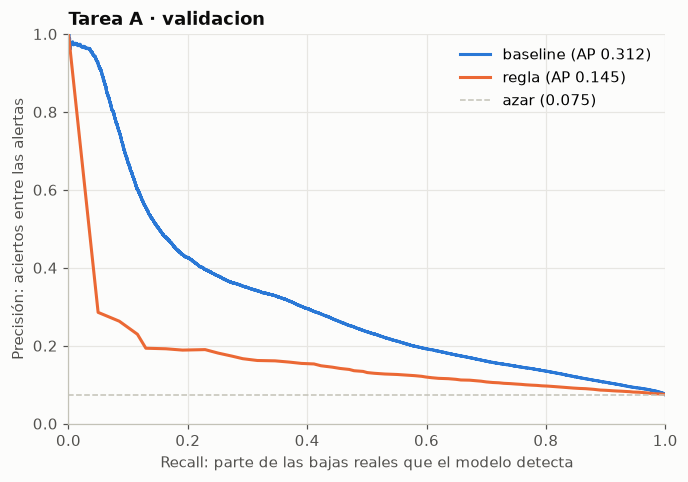

In [5]:
k = EVAL[-1]; x = pA[k]
fig, ax = plt.subplots(figsize=(7, 4.6))
for mod, col in (('baseline', AZUL), ('regla', NARANJA)):
    pr, rc, _ = precision_recall_curve(x.y_A, x[mod])
    ax.plot(rc, pr, color=col, label=f'{mod} (AP {average_precision_score(x.y_A, x[mod]):.3f})')
ax.axhline(x.y_A.mean(), color=GRIS, ls='--', lw=1, label=f'azar ({x.y_A.mean():.3f})')
ax.set_xlabel('Recall: parte de las bajas reales que el modelo detecta'); ax.set_ylabel('Precisión: aciertos entre las alertas')
ax.set_title(f'Tarea A · {k}'); ax.legend(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.show()

### 4. Lo que importa al negocio: aciertos por cada 100 alertas

Si el analista revisa solo los casos de mayor riesgo, ¿cuántos son bajas reales?

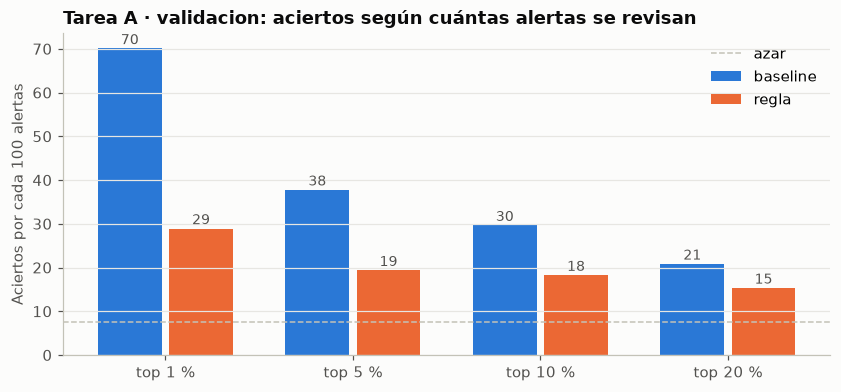

In [6]:
qs = [0.01, 0.05, 0.10, 0.20]
fig, ax = plt.subplots(figsize=(9, 3.8))
w = 0.38; xs = np.arange(len(qs))
for i, (mod, col) in enumerate((('baseline', AZUL), ('regla', NARANJA))):
    vals = [100 * top(x.y_A, x[mod], q) for q in qs]
    bars = ax.bar(xs + (i - 0.5) * w, vals, width=w - 0.04, color=col, label=mod)
    for r, v in zip(bars, vals):
        ax.text(r.get_x() + r.get_width() / 2, v + 1, f'{v:.0f}', ha='center', fontsize=9, color=TINTA2)
ax.axhline(100 * x.y_A.mean(), color=GRIS, ls='--', lw=1, label='azar')
ax.set_xticks(xs, [f'top {int(q * 100)} %' for q in qs]); ax.set_ylabel('Aciertos por cada 100 alertas'); ax.legend()
ax.set_title(f'Tarea A · {k}: aciertos según cuántas alertas se revisan'); ax.grid(axis='x', visible=False)
plt.show()

### 5. ¿En qué se fija el baseline?

Caída de la AP al desordenar cada variable (si cae mucho, la variable importa).

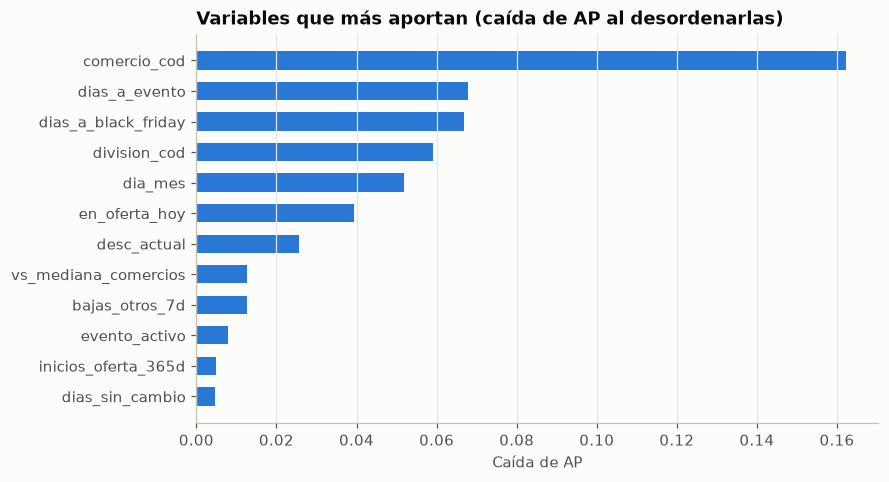

In [7]:
smp = cortes[EVAL[-1]].dropna(subset=['y_A']).sample(120000, random_state=7)
base = average_precision_score(smp.y_A, mA.predict_proba(smp[V.COLUMNAS])[:, 1]); rng = np.random.default_rng(7); imp = {}
for c in V.COLUMNAS:
    z = smp[V.COLUMNAS].copy(); z[c] = rng.permutation(z[c].values)
    imp[c] = base - average_precision_score(smp.y_A, mA.predict_proba(z)[:, 1])
imp = pd.Series(imp).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(imp.index, imp.values, color=AZUL, height=0.6); ax.grid(axis='y', visible=False)
ax.set_title('Variables que más aportan (caída de AP al desordenarlas)'); ax.set_xlabel('Caída de AP')
plt.show()

### 6. Un caso concreto

Probabilidad que da el baseline cada día para una serie, y los días en que de verdad bajó el precio.

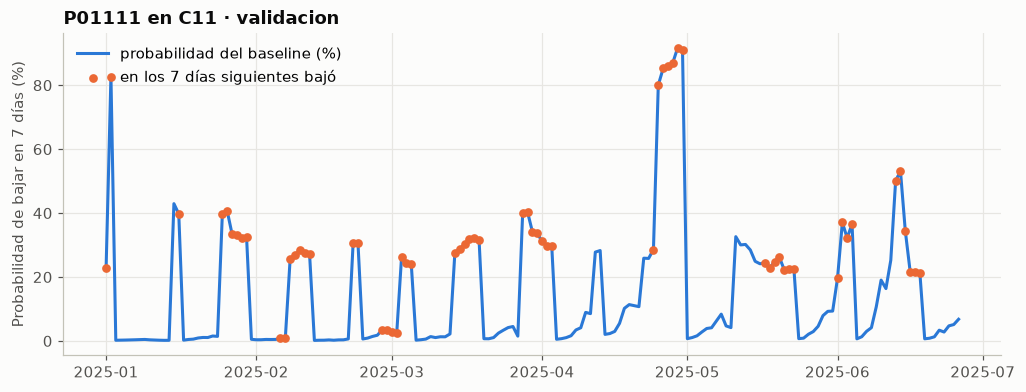

In [8]:
serie = x.groupby(['comercio_id', 'producto_id']).y_A.sum().idxmax()
g = x[(x.comercio_id == serie[0]) & (x.producto_id == serie[1])].sort_values('fecha')
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(g.fecha, 100 * g.baseline, color=AZUL, label='probabilidad del baseline (%)')
ax.scatter(g.fecha[g.y_A == 1], 100 * g.baseline[g.y_A == 1], s=22, color=NARANJA, zorder=3, label='en los 7 días siguientes bajó')
ax.set_title(f'{serie[1]} en {serie[0]} · {k}'); ax.set_ylabel('Probabilidad de bajar en 7 días (%)'); ax.legend(loc='upper left')
plt.show()

### 7. Tarea B: ¿baja mañana?

Más difícil (≈1 % de casos), pero es la que dice **la fecha**. Aquí el baseline deja más margen: hay patrones de día exacto (rezago entre comercios, duración de cada oferta, calendario por división) que casi no usa.

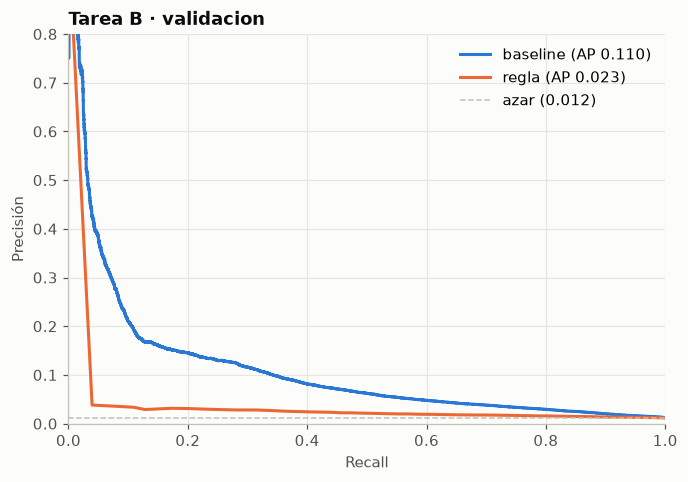

,corte,modelo,AP,AUC,aciertos por 100 alertas (top 5 %),azar (tasa base)
0,validacion,regla,0.023,0.661,2.956,1.184
1,validacion,baseline,0.110,0.820,8.930,1.184


In [9]:
mB, pB = entrenar('y_B')
tB = tabla(pB, 'y_B')
xb = pB[EVAL[-1]]
fig, ax = plt.subplots(figsize=(7, 4.6))
for mod, col in (('baseline', AZUL), ('regla', NARANJA)):
    pr, rc, _ = precision_recall_curve(xb.y_B, xb[mod])
    ax.plot(rc, pr, color=col, label=f'{mod} (AP {average_precision_score(xb.y_B, xb[mod]):.3f})')
ax.axhline(xb.y_B.mean(), color=GRIS, ls='--', lw=1, label=f'azar ({xb.y_B.mean():.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precisión'); ax.set_title(f'Tarea B · {EVAL[-1]}'); ax.legend(); ax.set_xlim(0, 1); ax.set_ylim(0, 0.8)
plt.show()
tB

## Resumen

- **Métrica a seguir: AP** (para elegir modelos) y **aciertos por cada 100 alertas** (para el negocio).
- El baseline ya supera claramente a la regla simple en las dos tareas.
- **Dónde mejorar:** la tarea B (la fecha exacta). Pistas: rezago entre comercios ("¿cuántos días hace que bajó otro?"), duración típica de las ofertas de cada comercio, calendario **por división** y precio frente al comercio más barato.